In [2]:
# First Execution Test 

print("Hello ! My first Machine Learning Assignment has started.")

import sys

print("Python version:", sys.version)

Hello ! My first Machine Learning Assignment has started.
Python version: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:27:36) [GCC 11.2.0]


In [2]:

# Step 5: Checking the required libraries

import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import sklearn
import scipy

print("All required libraries imported successfully!")

print("\nLibrary Versions:")
print("-------------------------")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)


All required libraries imported successfully!

Library Versions:
-------------------------
NumPy: 2.5.5
Pandas: 2.2.3
Matplotlib: 3.10.1
Seaborn: 0.13.2
Scikit-learn: 1.9.1
SciPy: 1.18.1


In [6]:

%pip install scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 114.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 157.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 100.3 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [10]:

%pip install --upgrade "numpy>=2.0,<2.8" scipy scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [4]:

import os
import urllib.request

# Create dataset folder
os.makedirs("data/raw", exist_ok=True)

# Official UCI download URL
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

# Destination
save_path = "data/raw/uci_bank_marketing.zip"

print("Connecting to UCI Repository...")

try:
    request = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=60) as response:
        with open(save_path, "wb") as file:
            file.write(response.read())

    print("Dataset downloaded successfully!")
    print("File size:", os.path.getsize(save_path), "bytes")

except Exception as e:
    print("Download failed.")
    print("Error:", e)


Connecting to UCI Repository...
Dataset downloaded successfully!
File size: 1023843 bytes


In [6]:

# STEP 2: Extract the Bank Marketing Dataset

import zipfile
import os

zip_path = "data/raw/uci_bank_marketing.zip"

# Open the downloaded ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:

    print("Files available in the ZIP archive:")
    
    for filename in zip_ref.namelist():
        print(filename)

    # Find the full additional dataset
    target_file = "bank-additional/bank-additional-full.csv"

    if target_file in zip_ref.namelist():

        # Extract the required CSV file
        zip_ref.extract(target_file, "data/raw")

        print("\nDataset extracted successfully!")

    else:
        print("\nRequired dataset file not found.")


Files available in the ZIP archive:
bank.zip
bank-additional.zip

Required dataset file not found.


In [8]:

# STEP 2: Extract the nested dataset ZIP file

import zipfile
import os

# Main downloaded ZIP file
main_zip = "data/raw/uci_bank_marketing.zip"

# Extract the inner ZIP file
with zipfile.ZipFile(main_zip, "r") as zip_ref:

    zip_ref.extract("bank-additional.zip", "data/raw")

print("Inner ZIP file extracted successfully!")

# Open the inner ZIP file
inner_zip = "data/raw/bank-additional.zip"

with zipfile.ZipFile(inner_zip, "r") as zip_ref:

    print("\nFiles inside bank-additional.zip:")

    for filename in zip_ref.namelist():
        print(filename)

    # Extract the complete dataset
    zip_ref.extractall("data/raw/bank-additional")

print("\nDataset extracted successfully!")

# Verify the CSV file
dataset_path = "data/raw/bank-additional/bank-additional-full.csv"

if os.path.exists(dataset_path):
    print("\nSUCCESS! Required CSV file is available.")
    print("File size:", round(os.path.getsize(dataset_path) / 1024, 2), "KB")
else:
    print("\nDataset file not found. Please check the output.")


Inner ZIP file extracted successfully!

Files inside bank-additional.zip:
bank-additional/
bank-additional/.DS_Store
__MACOSX/
__MACOSX/bank-additional/
__MACOSX/bank-additional/._.DS_Store
bank-additional/.Rhistory
bank-additional/bank-additional-full.csv
bank-additional/bank-additional-names.txt
bank-additional/bank-additional.csv
__MACOSX/._bank-additional

Dataset extracted successfully!

Dataset file not found. Please check the output.


In [10]:

# STEP 2.3: Locate the extracted dataset

import os

search_folder = "data/raw"

dataset_path = None

for root, dirs, files in os.walk(search_folder):
    if "bank-additional-full.csv" in files:
        dataset_path = os.path.join(
            root, "bank-additional-full.csv"
        )
        break

if dataset_path:
    print("SUCCESS! Dataset located.")
    print("\nActual dataset path:")
    print(dataset_path)

    print("\nFile size:",
          round(os.path.getsize(dataset_path) / 1024, 2),
          "KB")
else:
    print("Dataset not found.")


SUCCESS! Dataset located.

Actual dataset path:
data/raw/bank-additional/bank-additional/bank-additional-full.csv

File size: 5698.17 KB


In [12]:

# STEP 3: Load the Bank Marketing Dataset

import pandas as pd

# Read the CSV file
# Important: The UCI file uses semicolon (;) separators

df = pd.read_csv(dataset_path, sep=';')

print("Dataset loaded successfully!")

print("\nDataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nFirst 5 records:")
display(df.head())


Dataset loaded successfully!

Dataset dimensions:
Rows: 41188
Columns: 21

First 5 records:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [14]:

# STEP 4: Understand dataset structure

print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\n\nCOLUMN DATA TYPES")
print("=" * 50)

print(df.dtypes)


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.i

In [16]:

# STEP 5: Check missing values

print("MISSING VALUES ANALYSIS")
print("=" * 50)

# Count missing values in each column
missing_values = df.isnull().sum()

print(missing_values)

print("\nTotal missing values in dataset:")
print(missing_values.sum())


MISSING VALUES ANALYSIS
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Total missing values in dataset:
0


In [18]:

# STEP 5.2: Check unknown values

print("UNKNOWN VALUES ANALYSIS")
print("=" * 50)

for column in df.select_dtypes(include="object").columns:
    
    unknown_count = (df[column] == "unknown").sum()
    
    if unknown_count > 0:
        print(column, ":", unknown_count)


UNKNOWN VALUES ANALYSIS
job : 330
marital : 80
education : 1731
default : 8597
housing : 990
loan : 990


In [20]:

# STEP 6: Check duplicate records

print("DUPLICATE RECORD ANALYSIS")
print("=" * 50)

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

if duplicate_count > 0:
    print("\nDuplicate records detected.")
else:
    print("\nNo duplicate records found.")


DUPLICATE RECORD ANALYSIS
Total duplicate records: 12

Duplicate records detected.


In [22]:

# STEP 6.1: Remove duplicate records

# Create a backup of the original dataset
df_original = df.copy()

print("Records before removing duplicates:", len(df))

# Remove exact duplicate records
df = df.drop_duplicates()

print("Records after removing duplicates:", len(df))

# Verify duplicates
print("Remaining duplicate records:", df.duplicated().sum())


Records before removing duplicates: 41188
Records after removing duplicates: 41176
Remaining duplicate records: 0


In [24]:

# STEP 7: Target Variable Analysis

print("TARGET VARIABLE DISTRIBUTION")
print("=" * 50)

# Count each target category
print(df['y'].value_counts())

print("\nTarget variable percentages:")

# Calculate percentage distribution
print(df['y'].value_counts(normalize=True) * 100)


TARGET VARIABLE DISTRIBUTION
y
no     36537
yes     4639
Name: count, dtype: int64

Target variable percentages:
y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64


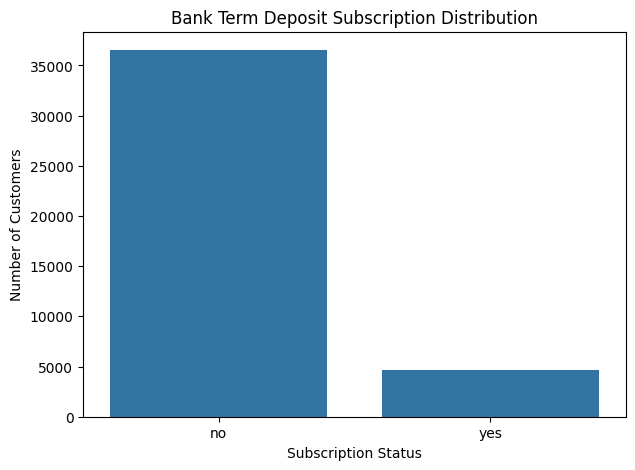

In [26]:

# Visualize target variable distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

plt.show()


In [28]:

print("Customer Subscription Analysis")
print("-" * 40)

counts = df['y'].value_counts()
percentages = df['y'].value_counts(normalize=True) * 100

print("Customer Counts:")
print(counts)

print("\nCustomer Percentages:")
print(percentages.round(2))


Customer Subscription Analysis
----------------------------------------
Customer Counts:
y
no     36537
yes     4639
Name: count, dtype: int64

Customer Percentages:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


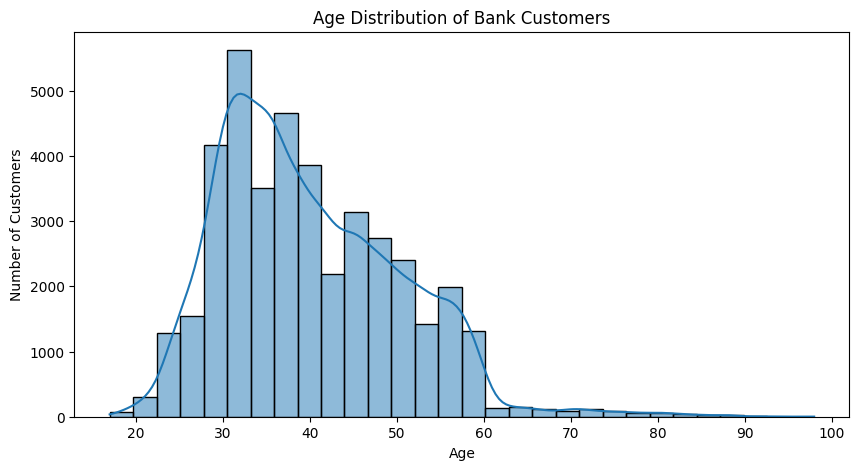

In [30]:

# STEP 8.1: Age Distribution

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Age Distribution of Bank Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()


In [32]:

# STEP 8.2: Age Statistical Summary

print("Age Statistical Summary")
print("-" * 35)

print(df['age'].describe())

print("\nMedian Age:", df['age'].median())
print("Most Common Age:", df['age'].mode()[0])
print("Skewness:", df['age'].skew())


Age Statistical Summary
-----------------------------------
count    41176.00000
mean        40.02380
std         10.42068
min         17.00000
25%         32.00000
50%         38.00000
75%         47.00000
max         98.00000
Name: age, dtype: float64

Median Age: 38.0
Most Common Age: 31
Skewness: 0.7845602604159752


Subscription Rate by Age Group (%)


y,no,yes
age_group,,
Below 25,79.04,20.96
25-35,88.28,11.72
35-45,91.49,8.51
45-55,91.31,8.69
Above 55,79.31,20.69


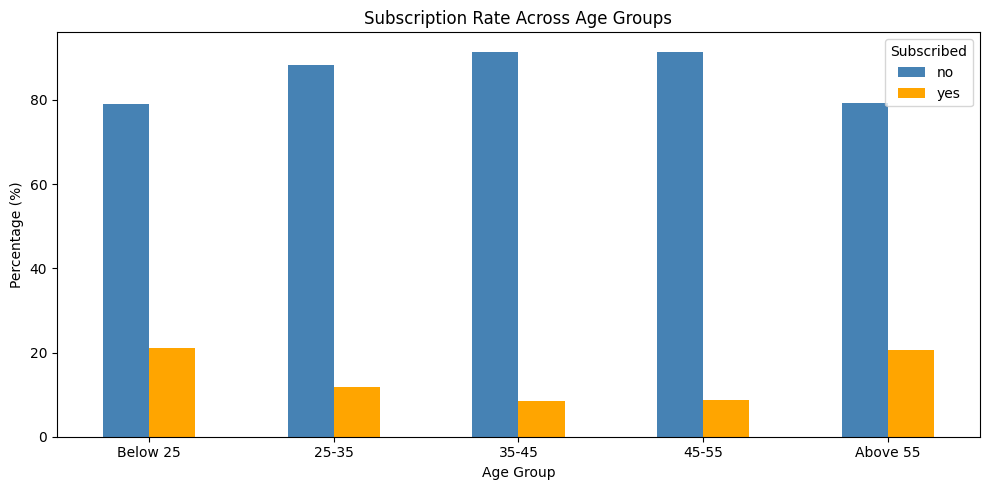

In [34]:

# STEP 8.3: Age vs Subscription

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 100],
    labels=['Below 25', '25-35', '35-45', '45-55', 'Above 55']
)

age_subscription = pd.crosstab(
    df['age_group'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Age Group (%)")
display(age_subscription.round(2))

# Visualization
age_subscription.plot(
    kind='bar',
    figsize=(10, 5),
    color=['steelblue', 'orange']
)

plt.title('Subscription Rate Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()


Subscription Rate by Job Category (%)


y,no,yes
job,,
admin.,87.03,12.97
blue-collar,93.10,6.90
entrepreneur,91.48,8.52
housemaid,90.00,10.00
management,88.78,11.22
retired,74.74,25.26
self-employed,89.51,10.49
services,91.86,8.14
student,68.57,31.43


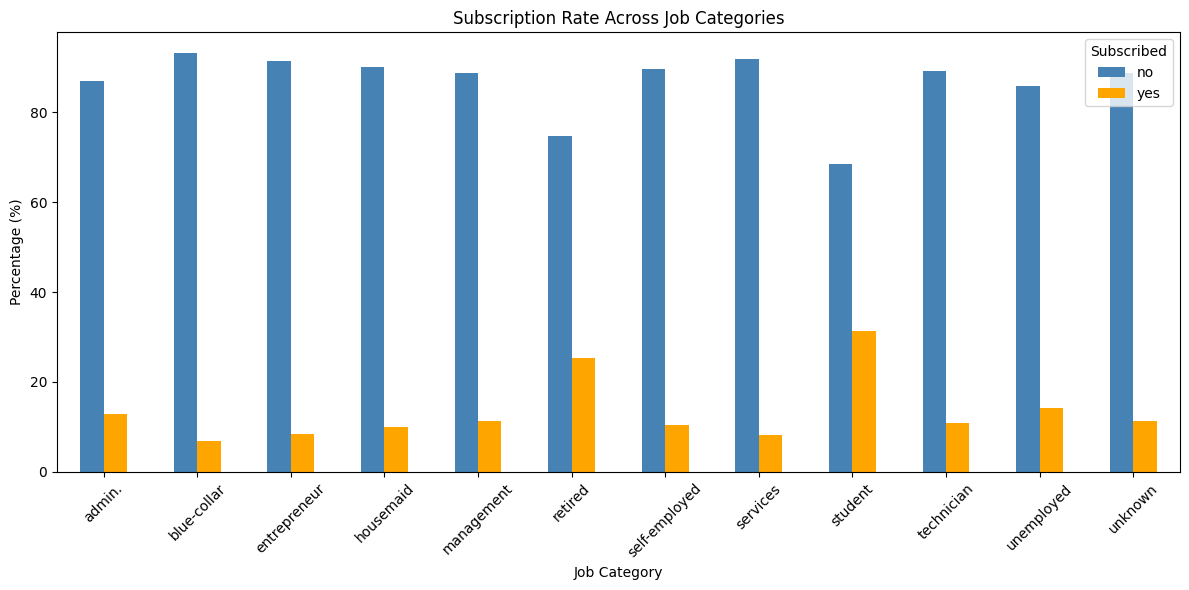

In [36]:

# STEP 8.4: Job vs Subscription

job_subscription = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Job Category (%)")
display(job_subscription.round(2))

# Visualization
job_subscription.plot(
    kind='bar',
    figsize=(12, 6),
    color=['steelblue', 'orange']
)

plt.title('Subscription Rate Across Job Categories')
plt.xlabel('Job Category')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()


Subscription Rate by Marital Status (%)


y,no,yes
marital,,
divorced,89.68,10.32
married,89.84,10.16
single,85.99,14.01
unknown,85.00,15.00


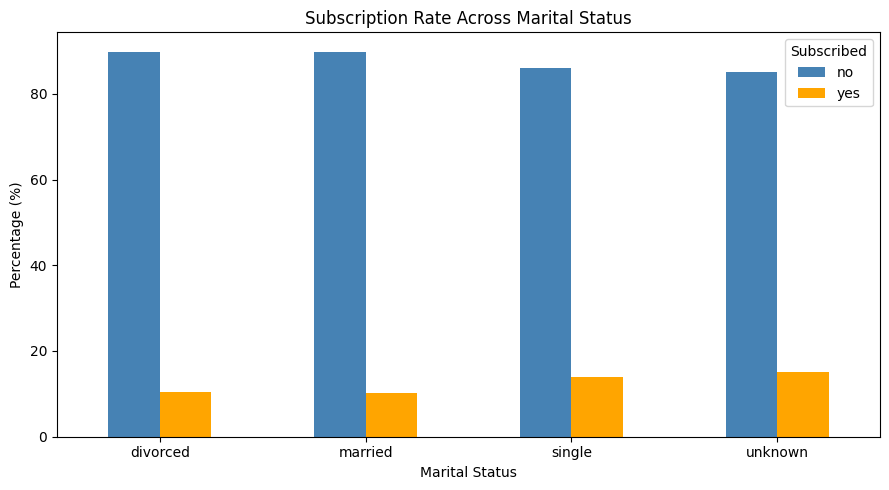

In [38]:

# STEP 8.5: Marital Status vs Subscription

marital_subscription = pd.crosstab(
    df['marital'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Marital Status (%)")
display(marital_subscription.round(2))

# Visualization
marital_subscription.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'orange']
)

plt.title('Subscription Rate Across Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()


Subscription Rate by Education (%)


y,no,yes
education,,
basic.4y,89.75,10.25
basic.6y,91.79,8.21
basic.9y,92.18,7.82
high.school,89.16,10.84
illiterate,77.78,22.22
professional.course,88.65,11.35
university.degree,86.28,13.72
unknown,85.49,14.51


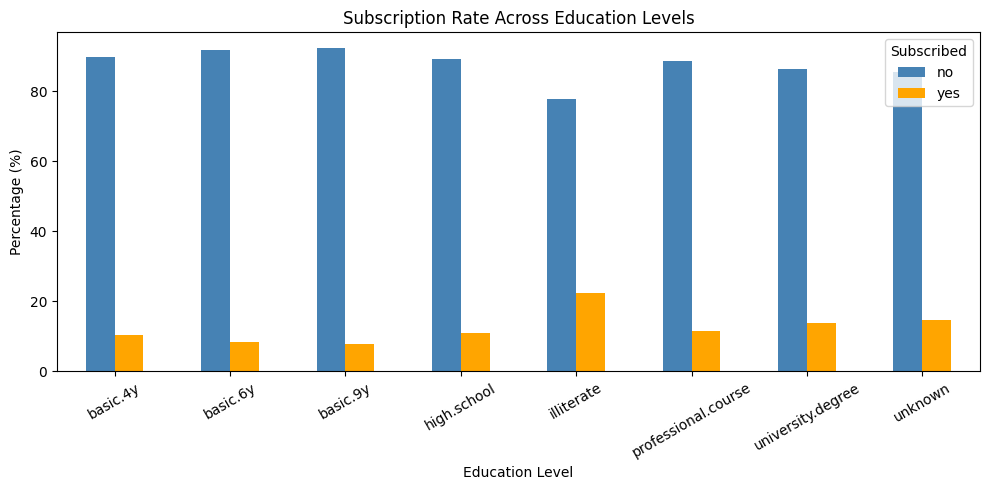

In [40]:

# STEP 8.6: Education vs Subscription

education_subscription = pd.crosstab(
    df['education'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Education (%)")
display(education_subscription.round(2))

# Visualization
education_subscription.plot(
    kind='bar',
    figsize=(10, 5),
    color=['steelblue', 'orange']
)

plt.title('Subscription Rate Across Education Levels')
plt.xlabel('Education Level')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=30)
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()


Subscription Rate Across Default Categories:
y            no    yes
default               
no        87.12  12.88
unknown   94.85   5.15
yes      100.00   0.00


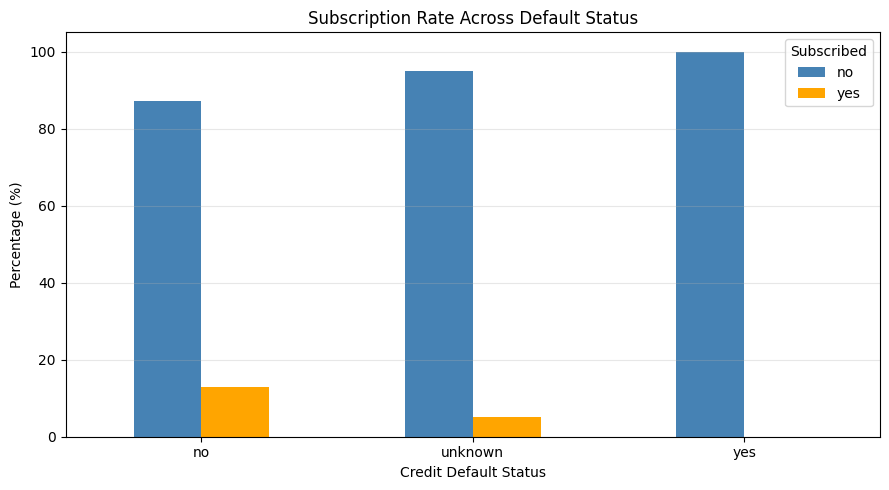

In [42]:

# STEP 5: Default Status vs Subscription Analysis

# Calculate subscription percentage for each default category
default_subscription = pd.crosstab(
    df['default'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate Across Default Categories:")
print(default_subscription.round(2))

# Visualize the results
default_subscription.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'orange']
)

plt.title("Subscription Rate Across Default Status")
plt.xlabel("Credit Default Status")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Subscribed")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Subscription Rate Across Housing Loan Categories:
y           no    yes
housing              
no       89.12  10.88
unknown  89.19  10.81
yes      88.38  11.62


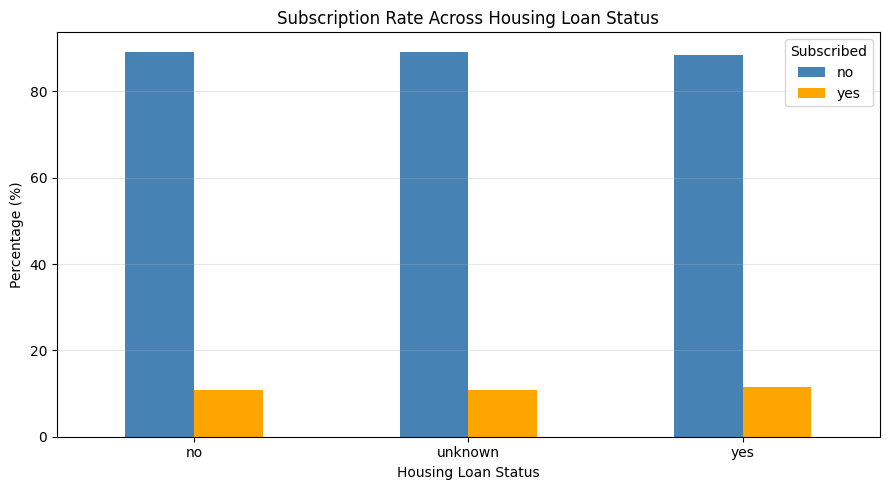

In [44]:

# STEP 6: Housing Loan vs Subscription Analysis

# Calculate subscription percentage
housing_subscription = pd.crosstab(
    df['housing'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate Across Housing Loan Categories:")
print(housing_subscription.round(2))

# Visualize the results
housing_subscription.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'orange']
)

plt.title("Subscription Rate Across Housing Loan Status")
plt.xlabel("Housing Loan Status")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Subscribed")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Subscription Rate Across Personal Loan Categories:
y           no    yes
loan                 
no       88.66  11.34
unknown  89.19  10.81
yes      89.07  10.93


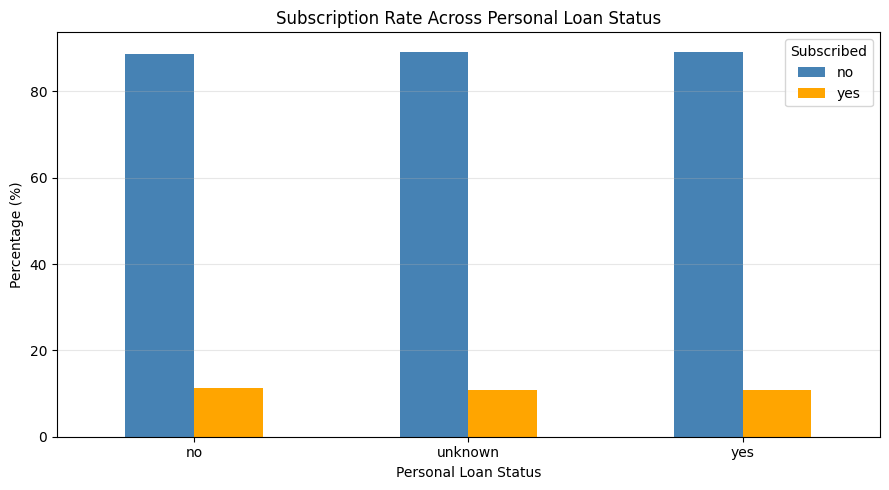

In [46]:

# STEP 7: Personal Loan vs Subscription Analysis

# Calculate subscription percentages
loan_subscription = pd.crosstab(
    df['loan'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate Across Personal Loan Categories:")
print(loan_subscription.round(2))

# Visualize the results
loan_subscription.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'orange']
)

plt.title("Subscription Rate Across Personal Loan Status")
plt.xlabel("Personal Loan Status")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Subscribed")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Subscription Rate Across Contact Types:
y             no    yes
contact                
cellular   85.26  14.74
telephone  94.77   5.23


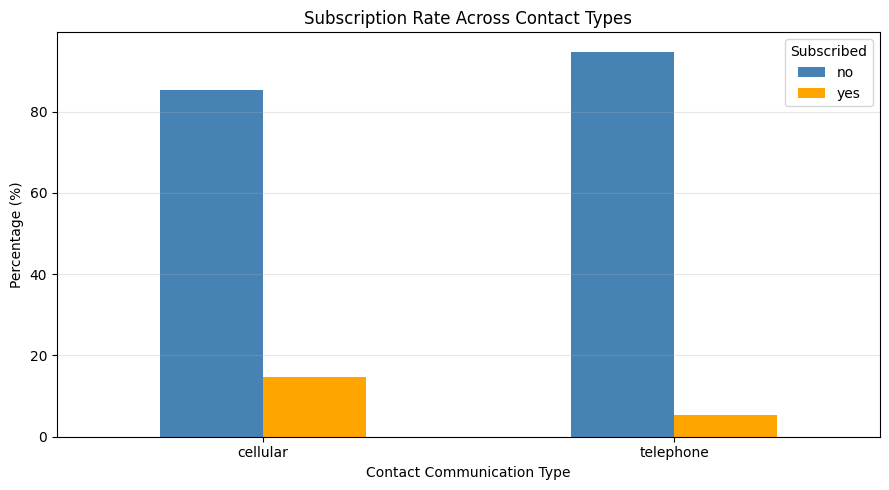

In [48]:

# STEP 8: Contact Type vs Subscription Analysis

# Calculate subscription percentages
contact_subscription = pd.crosstab(
    df['contact'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate Across Contact Types:")
print(contact_subscription.round(2))

# Visualize the results
contact_subscription.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'orange']
)

plt.title("Subscription Rate Across Contact Types")
plt.xlabel("Contact Communication Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Subscribed")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Subscription Rate Across Months:
y         no    yes
month              
apr    79.51  20.49
aug    89.39  10.61
dec    51.10  48.90
jul    90.96   9.04
jun    89.49  10.51
mar    49.45  50.55
may    93.56   6.44
nov    89.85  10.15
oct    56.07  43.93
sep    55.09  44.91


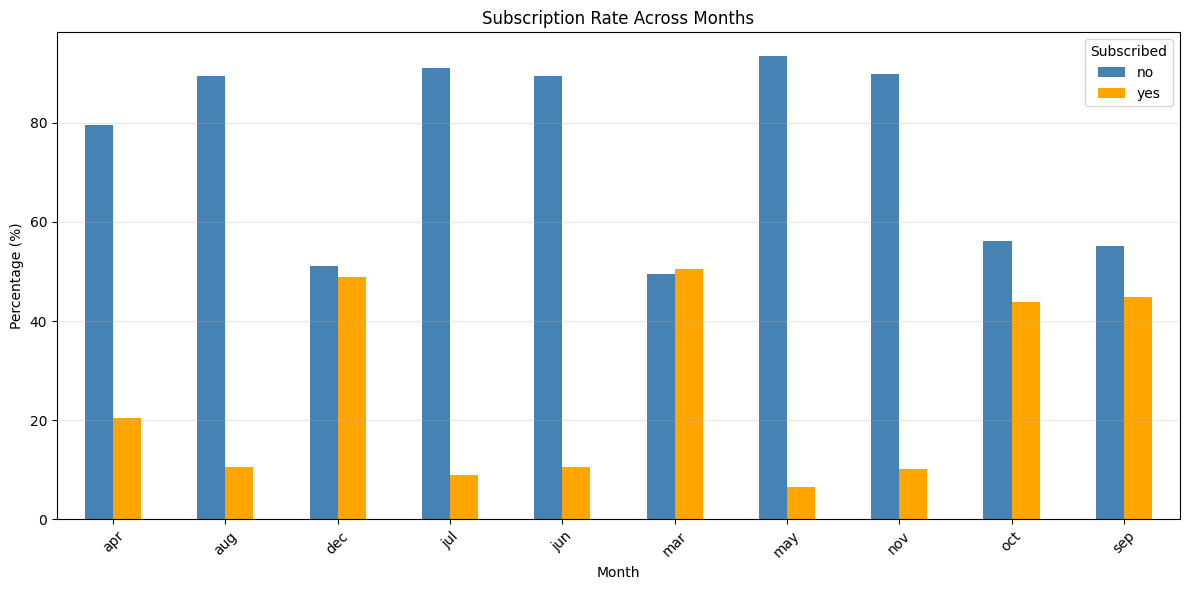

In [50]:

# STEP 9: Month vs Subscription Analysis

# Calculate subscription percentages
month_subscription = pd.crosstab(
    df['month'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate Across Months:")
print(month_subscription.round(2))

# Visualize the results
month_subscription.plot(
    kind='bar',
    figsize=(12, 6),
    color=['steelblue', 'orange']
)

plt.title("Subscription Rate Across Months")
plt.xlabel("Month")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Subscribed")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [52]:

# Exact monthly subscription analysis

monthly_analysis = pd.crosstab(
    df['month'],
    df['y'],
    margins=True
)

monthly_percentage = (
    pd.crosstab(df['month'], df['y'], normalize='index') * 100
)

print("Monthly Customer Counts:")
print(monthly_analysis)

print("\nMonthly Subscription Percentages:")
print(monthly_percentage.round(2))


Monthly Customer Counts:
y         no   yes    All
month                    
apr     2092   539   2631
aug     5521   655   6176
dec       93    89    182
jul     6521   648   7169
jun     4759   559   5318
mar      270   276    546
may    12881   886  13767
nov     3684   416   4100
oct      402   315    717
sep      314   256    570
All    36537  4639  41176

Monthly Subscription Percentages:
y         no    yes
month              
apr    79.51  20.49
aug    89.39  10.61
dec    51.10  48.90
jul    90.96   9.04
jun    89.49  10.51
mar    49.45  50.55
may    93.56   6.44
nov    89.85  10.15
oct    56.07  43.93
sep    55.09  44.91


In [54]:

# STEP 5.1: Day of Week vs Subscription Analysis

# Calculate subscription percentages for each day
day_analysis = pd.crosstab(
    df['day_of_week'],
    df['y'],
    normalize='index'
) * 100

# Display results
print("Subscription Rate Across Days of the Week:")
print(day_analysis.round(2))


Subscription Rate Across Days of the Week:
y               no    yes
day_of_week              
fri          89.19  10.81
mon          90.05   9.95
thu          87.89  12.11
tue          88.21  11.79
wed          88.33  11.67


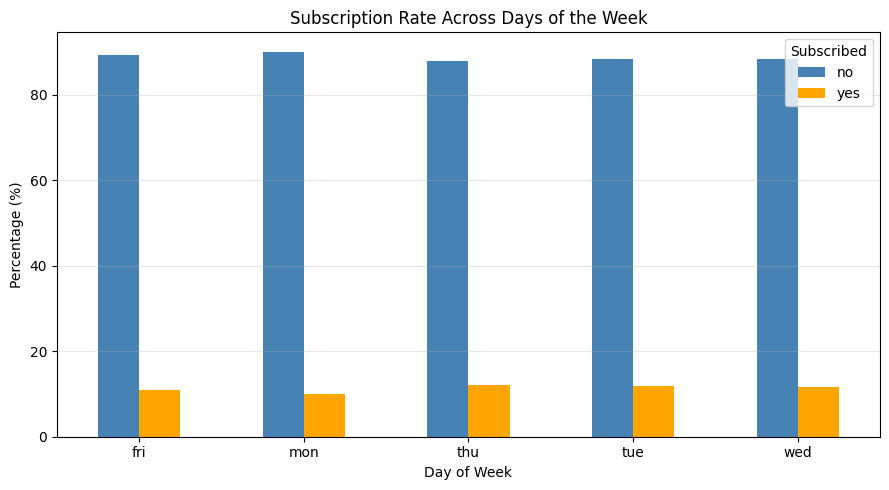

In [56]:

# Visualize subscription rates by day

day_analysis.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'orange']
)

plt.title('Subscription Rate Across Days of the Week')
plt.xlabel('Day of Week')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Subscribed')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [58]:

# STEP 6.1: Campaign Contact Distribution

print("Campaign Contact Statistics:")
print(df['campaign'].describe())

print("\nNumber of contacts distribution:")
print(df['campaign'].value_counts().sort_index().head(15))


Campaign Contact Statistics:
count    41176.000000
mean         2.567879
std          2.770318
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         56.000000
Name: campaign, dtype: float64

Number of contacts distribution:
campaign
1     17634
2     10568
3      5340
4      2650
5      1599
6       979
7       629
8       400
9       283
10      225
11      177
12      125
13       92
14       69
15       51
Name: count, dtype: int64


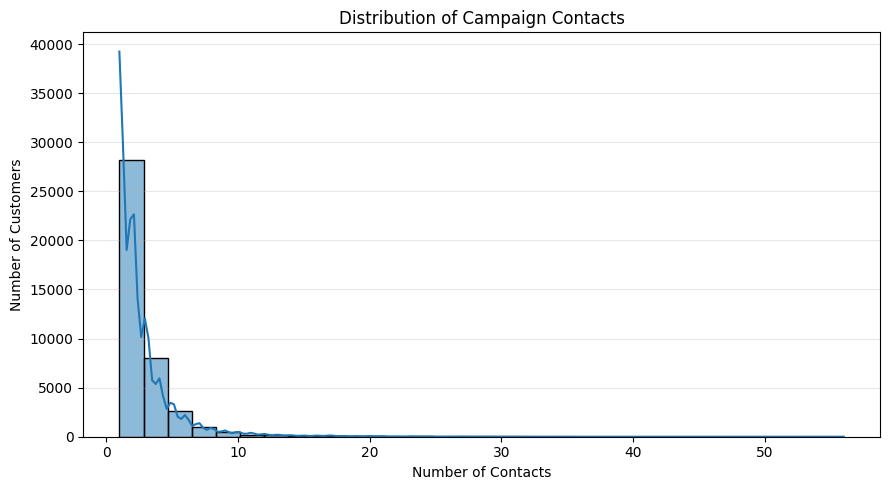

In [60]:

# STEP 6.2: Campaign Contact Distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    df['campaign'],
    bins=30,
    kde=True
)

plt.title('Distribution of Campaign Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [62]:

# STEP 6.3: Campaign Contacts vs Subscription

campaign_analysis = pd.crosstab(
    df['campaign'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Campaign Contacts:")
print(campaign_analysis.head(15).round(2))


Subscription Rate by Campaign Contacts:
y            no    yes
campaign              
1         86.96  13.04
2         88.54  11.46
3         89.25  10.75
4         90.60   9.40
5         92.50   7.50
6         92.34   7.66
7         93.96   6.04
8         95.75   4.25
9         93.99   6.01
10        94.67   5.33
11        93.22   6.78
12        97.60   2.40
13        95.65   4.35
14        98.55   1.45
15        96.08   3.92


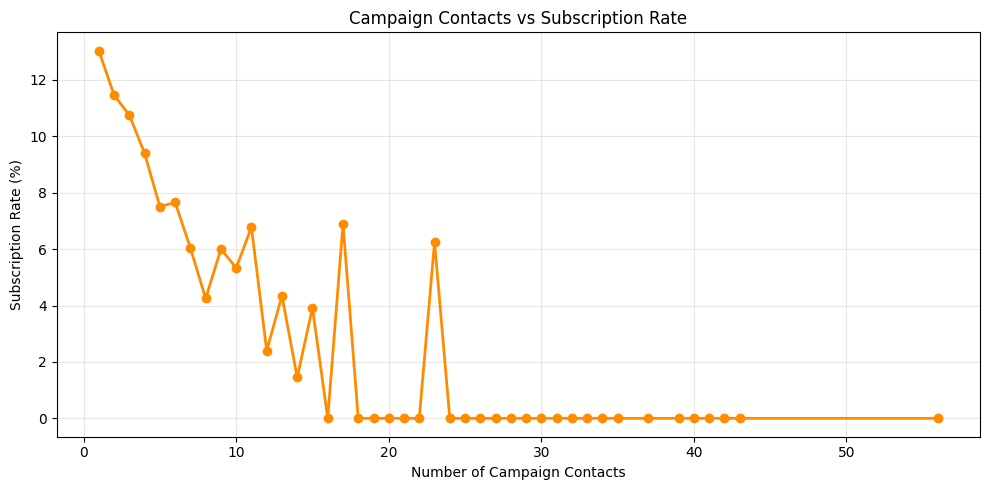

In [64]:

# STEP 6.4: Campaign Contacts vs Subscription Rate

plt.figure(figsize=(10, 5))

plt.plot(
    campaign_analysis.index,
    campaign_analysis['yes'],
    marker='o',
    linewidth=2,
    color='darkorange'
)

plt.title('Campaign Contacts vs Subscription Rate')
plt.xlabel('Number of Campaign Contacts')
plt.ylabel('Subscription Rate (%)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [66]:

# STEP 7.1: Previous Campaign Statistics

print("Previous Campaign Contacts:")
print(df['previous'].describe())

print("\nPrevious Contact Days Statistics:")
print(df['pdays'].describe())

print("\nPrevious Contact Distribution:")
print(df['previous'].value_counts().sort_index().head(15))


Previous Campaign Contacts:
count    41176.000000
mean         0.173013
std          0.494964
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          7.000000
Name: previous, dtype: float64

Previous Contact Days Statistics:
count    41176.000000
mean       962.464810
std        186.937102
min          0.000000
25%        999.000000
50%        999.000000
75%        999.000000
max        999.000000
Name: pdays, dtype: float64

Previous Contact Distribution:
previous
0    35551
1     4561
2      754
3      216
4       70
5       18
6        5
7        1
Name: count, dtype: int64


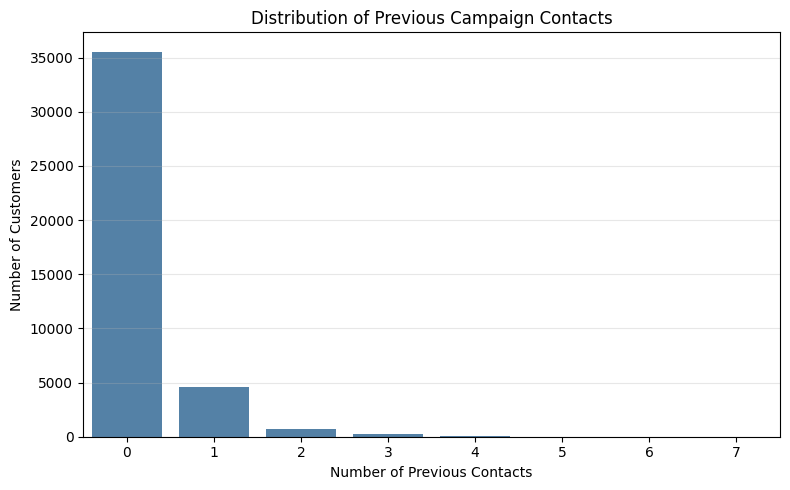

In [68]:

# STEP 7.2: Previous Campaign Contact Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    x='previous',
    data=df,
    color='steelblue'
)

plt.title('Distribution of Previous Campaign Contacts')
plt.xlabel('Number of Previous Contacts')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Subscription Rate by Previous Contacts:
y             no    yes
previous               
0          91.17   8.83
1          78.80  21.20
2          53.58  46.42
3          40.74  59.26
4          45.71  54.29
5          27.78  72.22
6          40.00  60.00
7         100.00    NaN


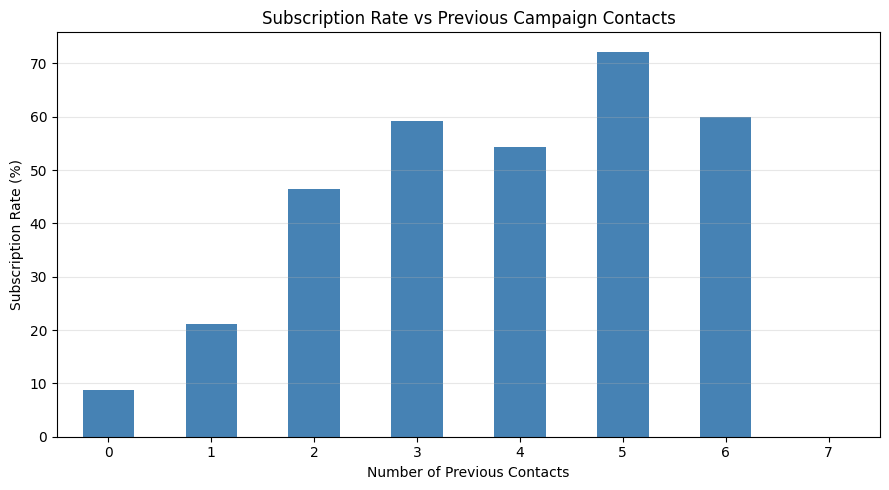

In [70]:

# STEP 7.3: Previous Contacts vs Subscription Rate

previous_analysis = df.groupby('previous')['y'].value_counts(
    normalize=True
).unstack() * 100

print("Subscription Rate by Previous Contacts:")
print(previous_analysis.round(2))

# Visualize subscription rate
previous_analysis['yes'].plot(
    kind='bar',
    figsize=(9, 5),
    color='steelblue'
)

plt.title('Subscription Rate vs Previous Campaign Contacts')
plt.xlabel('Number of Previous Contacts')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [72]:

# STEP 7.4: Previous Contact Days Analysis

print("Previous Contact Days Statistics:")
print(df['pdays'].describe())

print("\nPrevious Contact Days Distribution:")
print(df['pdays'].value_counts().sort_index().head(20))

print("\nNumber of customers never contacted previously:")
print((df['pdays'] == 999).sum())

print("\nNumber of customers contacted previously:")
print((df['pdays'] != 999).sum())


Previous Contact Days Statistics:
count    41176.000000
mean       962.464810
std        186.937102
min          0.000000
25%        999.000000
50%        999.000000
75%        999.000000
max        999.000000
Name: pdays, dtype: float64

Previous Contact Days Distribution:
pdays
0      15
1      26
2      61
3     439
4     118
5      46
6     412
7      60
8      18
9      64
10     52
11     28
12     58
13     36
14     20
15     24
16     11
17      8
18      7
19      3
Name: count, dtype: int64

Number of customers never contacted previously:
39661

Number of customers contacted previously:
1515


In [74]:

# Compare Subscription Rates

df['previously_contacted'] = df['pdays'].apply(
    lambda x: 'Previously Contacted' if x != 999
    else 'Never Contacted'
)

pdays_analysis = pd.crosstab(
    df['previously_contacted'],
    df['y'],
    normalize='index'
) * 100

print("Subscription Rate by Previous Contact Status:")
print(pdays_analysis.round(2))


Subscription Rate by Previous Contact Status:
y                        no    yes
previously_contacted              
Never Contacted       90.74   9.26
Previously Contacted  36.17  63.83


In [76]:

# STEP 7.5: Previous Campaign Outcome Analysis

print("Previous Campaign Outcome Distribution:")
print(df['poutcome'].value_counts())

print("\nSubscription Rate by Previous Campaign Outcome:")

poutcome_analysis = pd.crosstab(
    df['poutcome'],
    df['y'],
    normalize='index'
) * 100

print(poutcome_analysis.round(2))


Previous Campaign Outcome Distribution:
poutcome
nonexistent    35551
failure         4252
success         1373
Name: count, dtype: int64

Subscription Rate by Previous Campaign Outcome:
y               no    yes
poutcome                 
failure      85.77  14.23
nonexistent  91.17   8.83
success      34.89  65.11


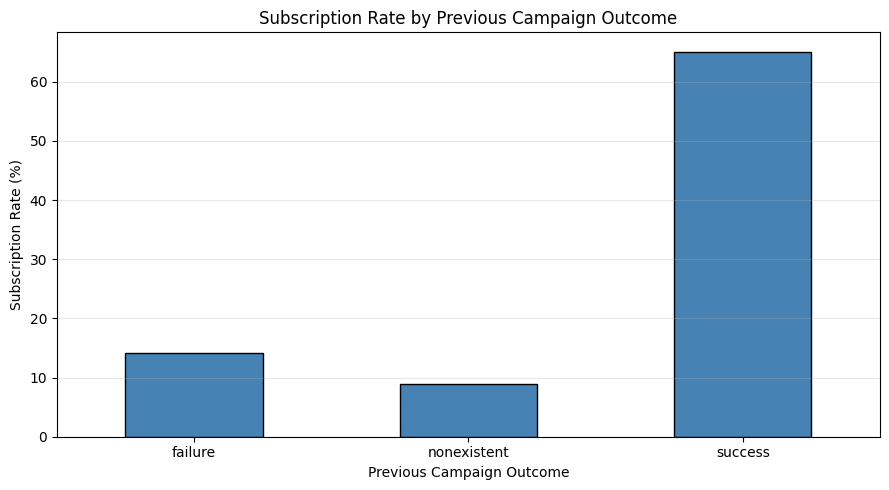

In [78]:

# STEP 7.6: Visualize Previous Campaign Outcome

plt.figure(figsize=(9, 5))

poutcome_analysis['yes'].plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Subscription Rate by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [80]:

# STEP 8.1: Identify Numerical Features

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nNumber of Numerical Features:")
print(len(numerical_columns))


Numerical Columns:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of Numerical Features:
10


In [82]:

# STEP 8.2: Correlation Matrix

correlation_matrix = df[numerical_columns].corr()

print("Correlation Matrix:")
print(correlation_matrix.round(2))


Correlation Matrix:
                 age  duration  campaign  pdays  previous  emp.var.rate  \
age             1.00     -0.00      0.00  -0.03      0.02         -0.00   
duration       -0.00      1.00     -0.07  -0.05      0.02         -0.03   
campaign        0.00     -0.07      1.00   0.05     -0.08          0.15   
pdays          -0.03     -0.05      0.05   1.00     -0.59          0.27   
previous        0.02      0.02     -0.08  -0.59      1.00         -0.42   
emp.var.rate   -0.00     -0.03      0.15   0.27     -0.42          1.00   
cons.price.idx  0.00      0.01      0.13   0.08     -0.20          0.78   
cons.conf.idx   0.13     -0.01     -0.01  -0.09     -0.05          0.20   
euribor3m       0.01     -0.03      0.14   0.30     -0.45          0.97   
nr.employed    -0.02     -0.04      0.14   0.37     -0.50          0.91   

                cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
age                       0.00           0.13       0.01        -0.02  
duration  

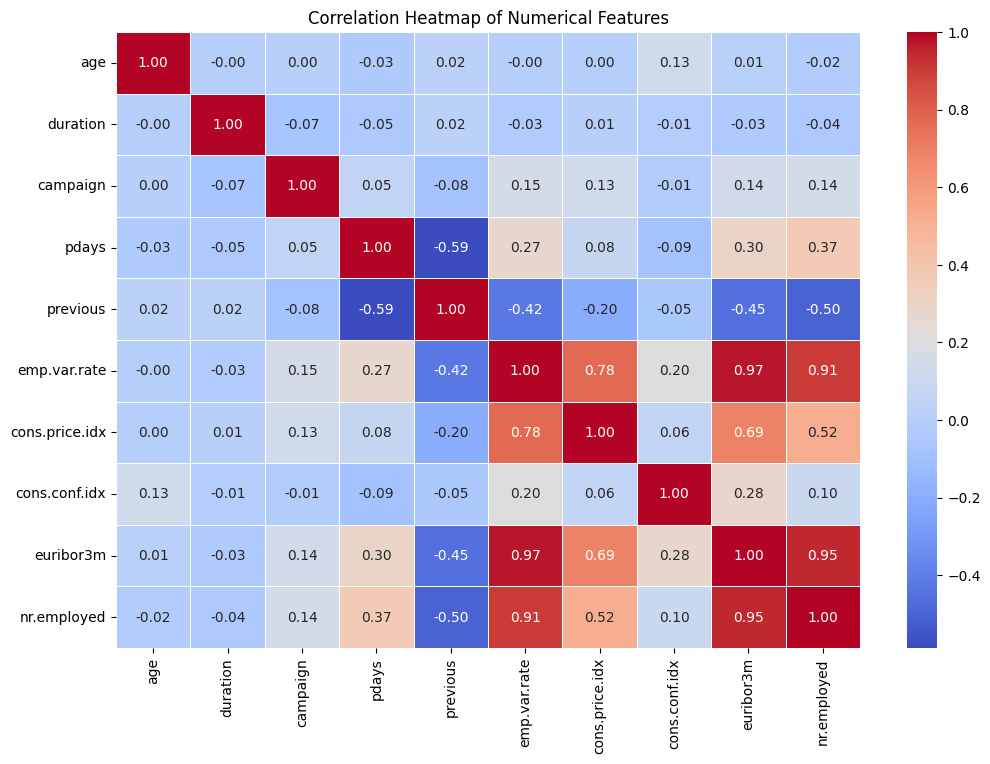

In [84]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()


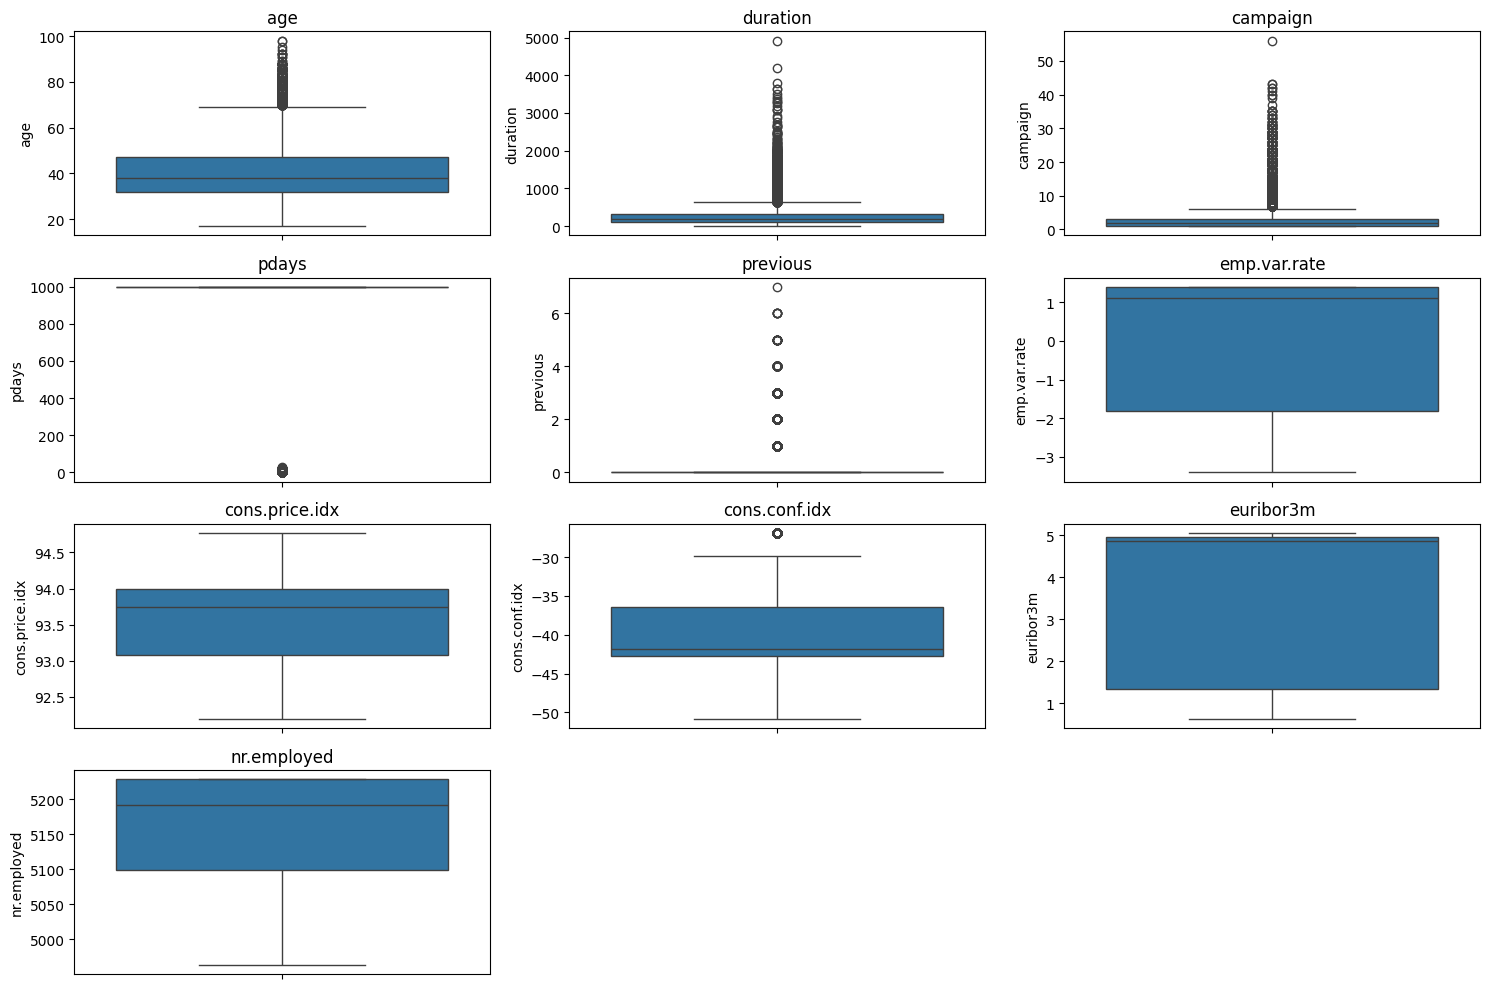

In [86]:

# STEP 8.3: Detect Outliers Using Boxplots

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [88]:

# STEP 8.4: Check Missing Values

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())


Missing Values in Each Column:
age                     0
job                     0
marital                 0
education               0
default                 0
housing                 0
loan                    0
contact                 0
month                   0
day_of_week             0
duration                0
campaign                0
pdays                   0
previous                0
poutcome                0
emp.var.rate            0
cons.price.idx          0
cons.conf.idx           0
euribor3m               0
nr.employed             0
y                       0
age_group               0
previously_contacted    0
dtype: int64

Total Missing Values:
0

Number of Duplicate Rows:
0


In [90]:

# STEP 8.5: Check Unknown Values in Categorical Columns

categorical_columns = df.select_dtypes(
    include=['object']
).columns

for col in categorical_columns:
    unknown_count = (df[col] == 'unknown').sum()
    
    if unknown_count > 0:
        print(f"{col}: {unknown_count} unknown values")


job: 330 unknown values
marital: 80 unknown values
education: 1730 unknown values
default: 8596 unknown values
housing: 990 unknown values
loan: 990 unknown values


In [92]:

# STEP 8.6: Unknown Values vs Subscription

unknown_analysis = {}

for col in categorical_columns:
    if (df[col] == 'unknown').sum() > 0:
        
        analysis = pd.crosstab(
            df[col],
            df['y'],
            normalize='index'
        ) * 100
        
        unknown_analysis[col] = analysis.loc['unknown'].round(2)

print("Subscription Rate for Unknown Categories:")

for col, result in unknown_analysis.items():
    print(f"\n{col}:")
    print(result)


Subscription Rate for Unknown Categories:

job:
y
no     88.79
yes    11.21
Name: unknown, dtype: float64

marital:
y
no     85.0
yes    15.0
Name: unknown, dtype: float64

education:
y
no     85.49
yes    14.51
Name: unknown, dtype: float64

default:
y
no     94.85
yes     5.15
Name: unknown, dtype: float64

housing:
y
no     89.19
yes    10.81
Name: unknown, dtype: float64

loan:
y
no     89.19
yes    10.81
Name: unknown, dtype: float64


In [94]:

# STEP 9.1: Separate Features and Target Variable

from sklearn.model_selection import train_test_split

# Separate independent and dependent variables
X = df.drop(columns=['y'])
y = df['y'].map({'no': 0, 'yes': 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Perform 80:20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining and Testing Dataset Shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check target distribution
print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Features shape: (41176, 22)
Target shape: (41176,)

Training and Testing Dataset Shapes:
X_train: (32940, 22)
X_test: (8236, 22)
y_train: (32940,)
y_test: (8236,)

Training Target Distribution:
y
0    88.734062
1    11.265938
Name: proportion, dtype: float64

Testing Target Distribution:
y
0    88.732394
1    11.267606
Name: proportion, dtype: float64


In [96]:

# STEP 9.2: Categorical Encoding and Numerical Feature Scaling

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

# Numerical preprocessing pipeline
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing Completed Successfully!")

print("Processed Training Data Shape:", X_train_processed.shape)
print("Processed Testing Data Shape:", X_test_processed.shape)

print("\nMissing Values After Preprocessing:")
print("Training:", np.isnan(X_train_processed).sum())
print("Testing:", np.isnan(X_test_processed).sum())


Numerical Features: 10
Categorical Features: 11

Preprocessing Completed Successfully!
Processed Training Data Shape: (32940, 65)
Processed Testing Data Shape: (8236, 65)

Missing Values After Preprocessing:
Training: 0
Testing: 0


In [98]:

# STEP 9.3: Final Preprocessing Verification

print("Final Preprocessing Summary")
print("-" * 40)

print("Training Features:", X_train_processed.shape)
print("Testing Features:", X_test_processed.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTarget Classes:", np.unique(y_train))

print("\nChecking for infinite values:")
print("Training:", np.isinf(X_train_processed).sum())
print("Testing:", np.isinf(X_test_processed).sum())

print("\nClass Distribution in Training Data:")
print(y_train.value_counts(normalize=True) * 100)

print("\nClass Distribution in Testing Data:")
print(y_test.value_counts(normalize=True) * 100)

print("\nFinal preprocessing verification completed!")


Final Preprocessing Summary
----------------------------------------
Training Features: (32940, 65)
Testing Features: (8236, 65)

Training Target Shape: (32940,)
Testing Target Shape: (8236,)

Target Classes: [0 1]

Checking for infinite values:
Training: 0
Testing: 0

Class Distribution in Training Data:
y
0    88.734062
1    11.265938
Name: proportion, dtype: float64

Class Distribution in Testing Data:
y
0    88.732394
1    11.267606
Name: proportion, dtype: float64

Final preprocessing verification completed!


In [100]:

# STEP 10.1: Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

# Make predictions
y_pred_lr = logistic_model.predict(X_test_processed)

# Evaluate the model
print("LOGISTIC REGRESSION RESULTS")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


LOGISTIC REGRESSION RESULTS
----------------------------------------
Accuracy: 0.9090577950461389
Precision: 0.648424543946932
Recall: 0.4213362068965517
F1 Score: 0.5107772697583279

Confusion Matrix:
[[7096  212]
 [ 537  391]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      7308
           1       0.65      0.42      0.51       928

    accuracy                           0.91      8236
   macro avg       0.79      0.70      0.73      8236
weighted avg       0.90      0.91      0.90      8236



In [102]:

# STEP 10.2: Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train_processed, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test_processed)

# Evaluate the model
print("DECISION TREE RESULTS")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


DECISION TREE RESULTS
----------------------------------------
Accuracy: 0.8890237979601748
Precision: 0.507399577167019
Recall: 0.5172413793103449
F1 Score: 0.512273212379936

Confusion Matrix:
[[6842  466]
 [ 448  480]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      7308
           1       0.51      0.52      0.51       928

    accuracy                           0.89      8236
   macro avg       0.72      0.73      0.72      8236
weighted avg       0.89      0.89      0.89      8236



In [104]:

# STEP 10.3: K-Nearest Neighbors Classifier

from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

# Train the model
knn_model.fit(X_train_processed, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test_processed)

# Evaluate the model
print("K-NEAREST NEIGHBORS RESULTS")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("F1 Score:", f1_score(y_test, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))


K-NEAREST NEIGHBORS RESULTS
----------------------------------------
Accuracy: 0.9014084507042254
Precision: 0.5857988165680473
Recall: 0.4267241379310345
F1 Score: 0.4937655860349127

Confusion Matrix:
[[7028  280]
 [ 532  396]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      7308
           1       0.59      0.43      0.49       928

    accuracy                           0.90      8236
   macro avg       0.76      0.69      0.72      8236
weighted avg       0.89      0.90      0.89      8236



In [106]:

# STEP 10.4: Naive Bayes Classifier

from sklearn.naive_bayes import GaussianNB

# Create Naive Bayes model
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train_processed, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test_processed)

# Evaluate the model
print("NAIVE BAYES RESULTS")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1 Score:", f1_score(y_test, y_pred_nb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))


NAIVE BAYES RESULTS
----------------------------------------
Accuracy: 0.8476202039825158
Precision: 0.3841247342310418
Recall: 0.584051724137931
F1 Score: 0.463445917058572

Confusion Matrix:
[[6439  869]
 [ 386  542]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.88      0.91      7308
           1       0.38      0.58      0.46       928

    accuracy                           0.85      8236
   macro avg       0.66      0.73      0.69      8236
weighted avg       0.88      0.85      0.86      8236



In [108]:

# STEP 10.5: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test_processed)

# Evaluate the model
print("RANDOM FOREST RESULTS")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


RANDOM FOREST RESULTS
----------------------------------------
Accuracy: 0.9140359397765906
Precision: 0.6651651651651652
Recall: 0.47737068965517243
F1 Score: 0.5558343789209536

Confusion Matrix:
[[7085  223]
 [ 485  443]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      7308
           1       0.67      0.48      0.56       928

    accuracy                           0.91      8236
   macro avg       0.80      0.72      0.75      8236
weighted avg       0.91      0.91      0.91      8236



In [110]:

# STEP 11: Model Performance Comparison

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Store model performance metrics
model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Naive Bayes',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_rf)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_rf)
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(model_results.round(4))


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9091,0.6484,0.4213,0.5108
1,Decision Tree,0.8890,0.5074,0.5172,0.5123
2,KNN,0.9014,0.5858,0.4267,0.4938
3,Naive Bayes,0.8476,0.3841,0.5841,0.4634
4,Random Forest,0.9140,0.6652,0.4774,0.5558


<Figure size 1400x700 with 0 Axes>

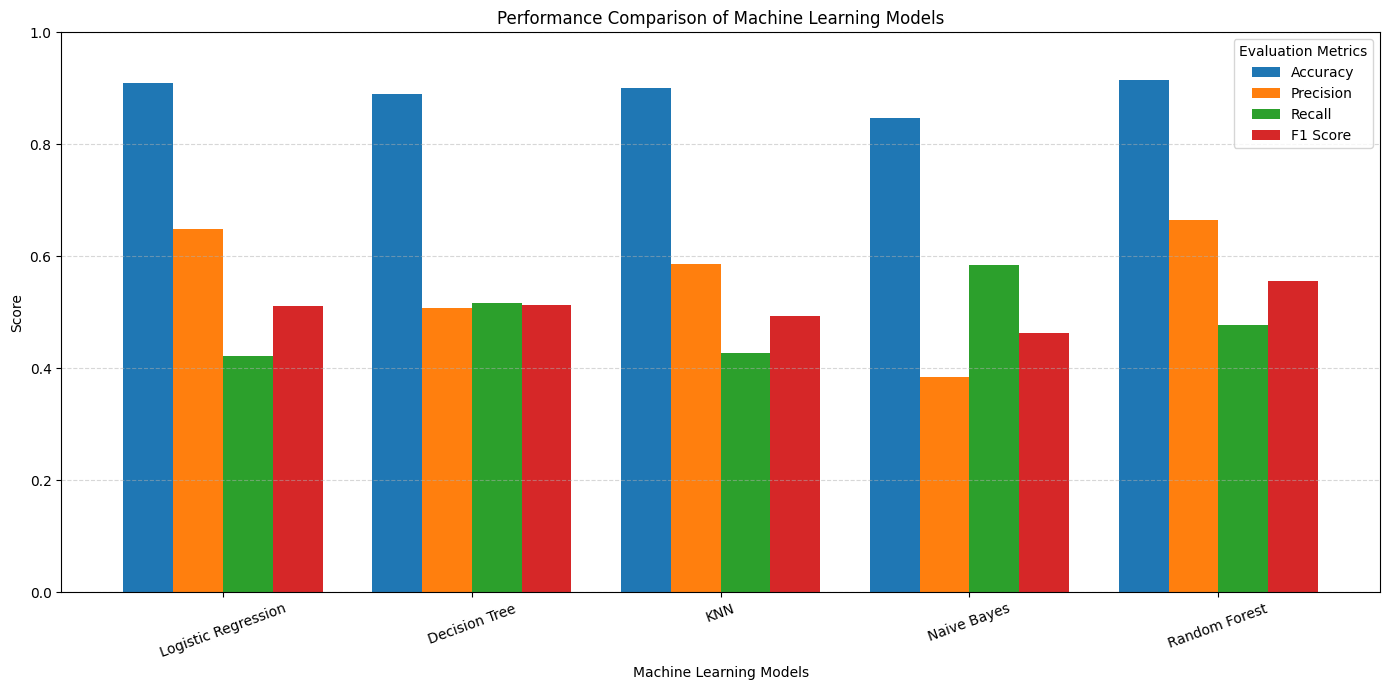

In [112]:

# STEP 12: Visual Comparison of Model Performance

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

plt.figure(figsize=(14, 7))

model_results.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title('Performance Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [114]:

# STEP 13: Identify the Best Performing Model

best_model = model_results.loc[
    model_results['F1 Score'].idxmax()
]

print("BEST PERFORMING MODEL")
print("----------------------")
print("Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1 Score:", round(best_model['F1 Score'], 4))


BEST PERFORMING MODEL
----------------------
Model: Random Forest
Accuracy: 0.914
Precision: 0.6652
Recall: 0.4774
F1 Score: 0.5558


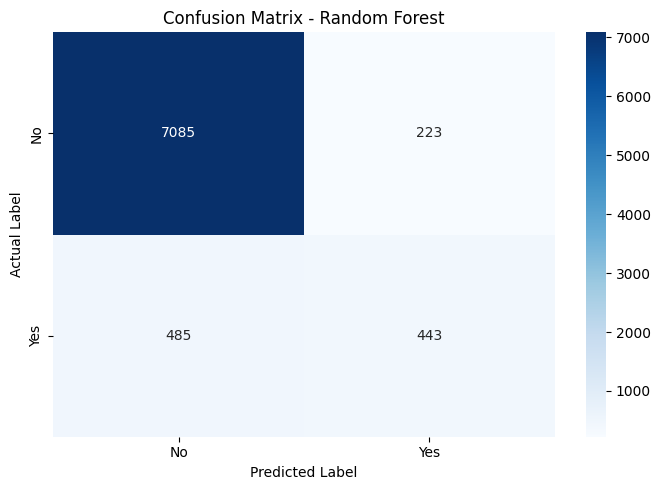

In [116]:

# STEP 14: Confusion Matrix Visualization for Random Forest

from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()


In [118]:

# STEP 15: Calculate AUC and MCC for All Five Models

from sklearn.metrics import roc_auc_score, matthews_corrcoef

# Calculate AUC using predicted probabilities
# Calculate MCC using predicted class labels

auc_mcc_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Naive Bayes',
        'Random Forest'
    ],

    'AUC': [
        roc_auc_score(y_test, logistic_model.predict_proba(X_test_processed)[:, 1]),
        roc_auc_score(y_test, dt_model.predict_proba(X_test_processed)[:, 1]),
        roc_auc_score(y_test, knn_model.predict_proba(X_test_processed)[:, 1]),
        roc_auc_score(y_test, nb_model.predict_proba(X_test_processed)[:, 1]),
        roc_auc_score(y_test, rf_model.predict_proba(X_test_processed)[:, 1])
    ],

    'MCC': [
        matthews_corrcoef(y_test, y_pred_lr),
        matthews_corrcoef(y_test, y_pred_dt),
        matthews_corrcoef(y_test, y_pred_knn),
        matthews_corrcoef(y_test, y_pred_nb),
        matthews_corrcoef(y_test, y_pred_rf)
    ]
})

print("AUC AND MCC COMPARISON")
print("------------------------------")
display(auc_mcc_results.round(4))


AUC AND MCC COMPARISON
------------------------------


,Model,AUC,MCC
0,Logistic Regression,0.9390,0.4762
1,Decision Tree,0.7267,0.4497
2,KNN,0.8741,0.4474
3,Naive Bayes,0.8405,0.3903
4,Random Forest,0.9424,0.5183


In [120]:

# STEP 16: Combine All Evaluation Metrics

final_model_results = pd.merge(
    model_results,
    auc_mcc_results,
    on='Model'
)

print("FINAL MODEL PERFORMANCE COMPARISON")
print("-----------------------------------")

display(final_model_results.round(4))


FINAL MODEL PERFORMANCE COMPARISON
-----------------------------------


,Model,Accuracy,Precision,Recall,F1 Score,AUC,MCC
0,Logistic Regression,0.9091,0.6484,0.4213,0.5108,0.9390,0.4762
1,Decision Tree,0.8890,0.5074,0.5172,0.5123,0.7267,0.4497
2,KNN,0.9014,0.5858,0.4267,0.4938,0.8741,0.4474
3,Naive Bayes,0.8476,0.3841,0.5841,0.4634,0.8405,0.3903
4,Random Forest,0.9140,0.6652,0.4774,0.5558,0.9424,0.5183


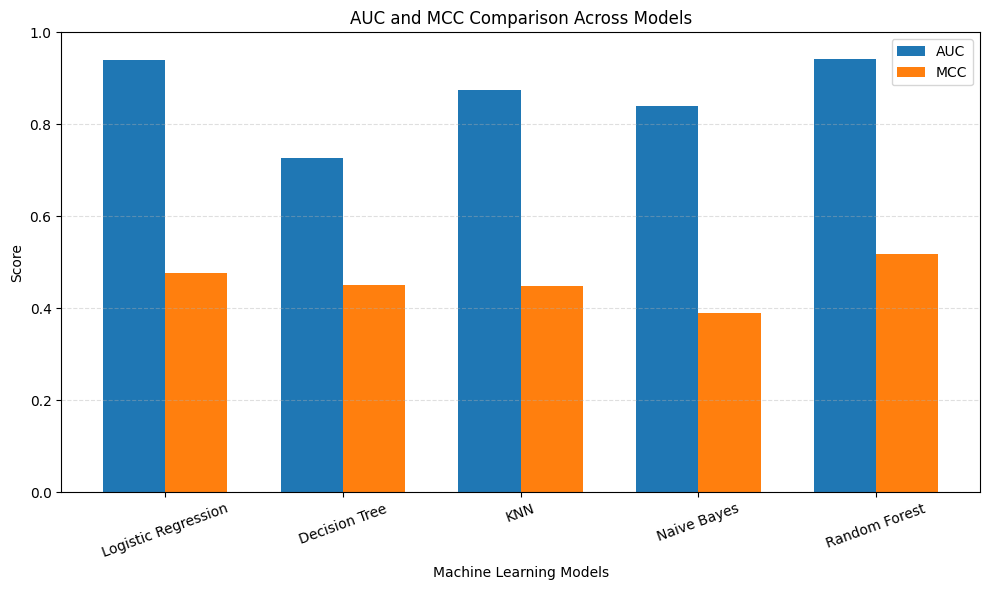

In [122]:

# STEP 17: AUC and MCC Comparison Graph

plt.figure(figsize=(10, 6))

x = np.arange(len(final_model_results['Model']))
width = 0.35

plt.bar(
    x - width/2,
    final_model_results['AUC'],
    width,
    label='AUC'
)

plt.bar(
    x + width/2,
    final_model_results['MCC'],
    width,
    label='MCC'
)

plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.title('AUC and MCC Comparison Across Models')

plt.xticks(
    x,
    final_model_results['Model'],
    rotation=20
)

plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [124]:

# STEP 18: Model Performance Interpretation

print("MODEL PERFORMANCE INTERPRETATION")
print("--------------------------------")

for _, row in final_model_results.iterrows():
    print(f"\nModel: {row['Model']}")
    print(f"Accuracy: {row['Accuracy']:.4f}")
    print(f"Precision: {row['Precision']:.4f}")
    print(f"Recall: {row['Recall']:.4f}")
    print(f"F1 Score: {row['F1 Score']:.4f}")
    print(f"AUC: {row['AUC']:.4f}")
    print(f"MCC: {row['MCC']:.4f}")

print("\nOVERALL CONCLUSION")
print("------------------")
print("Random Forest achieved the highest F1 Score, AUC and MCC.")
print("It demonstrated the strongest overall performance among the")
print("five evaluated classification models.")


MODEL PERFORMANCE INTERPRETATION
--------------------------------

Model: Logistic Regression
Accuracy: 0.9091
Precision: 0.6484
Recall: 0.4213
F1 Score: 0.5108
AUC: 0.9390
MCC: 0.4762

Model: Decision Tree
Accuracy: 0.8890
Precision: 0.5074
Recall: 0.5172
F1 Score: 0.5123
AUC: 0.7267
MCC: 0.4497

Model: KNN
Accuracy: 0.9014
Precision: 0.5858
Recall: 0.4267
F1 Score: 0.4938
AUC: 0.8741
MCC: 0.4474

Model: Naive Bayes
Accuracy: 0.8476
Precision: 0.3841
Recall: 0.5841
F1 Score: 0.4634
AUC: 0.8405
MCC: 0.3903

Model: Random Forest
Accuracy: 0.9140
Precision: 0.6652
Recall: 0.4774
F1 Score: 0.5558
AUC: 0.9424
MCC: 0.5183

OVERALL CONCLUSION
------------------
Random Forest achieved the highest F1 Score, AUC and MCC.
It demonstrated the strongest overall performance among the
five evaluated classification models.
